In [1]:
## Mini proyecto de análisis de datos utilizando un conjunto de datos proporcionado por INTERCONECTA ##

In [2]:
1. # Preparación del entorno y librerias de R 
if (!require("tidyverse")) install.packages("tidyverse")
library(tidyverse)
library(ggplot2)

[1] 1

Loading required package: tidyverse

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.1     ✔ stringr   1.5.2
✔ ggplot2   4.0.0     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.1.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [3]:
dplyr::filter(mtcars, am & cyl == 8)
#>                 mpg cyl disp  hp drat   wt qsec vs am gear carb
#> Ford Pantera L 15.8   8  351 264 4.22 3.17 14.5  0  1    5    4
#> Maserati Bora  15.0   8  301 335 3.54 3.57 14.6  0  1    5    8

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Ford Pantera L,15.8,8,351,264,4.22,3.17,14.5,0,1,5,4
Maserati Bora,15.0,8,301,335,3.54,3.57,14.6,0,1,5,8


In [4]:
# 2.-Craeación de la estructura requerida

if (!dir.exists("datos")) dir.create("datos")
if (!dir.exists("figuras")) dir.create("figuras")

In [5]:
## 3. Cargando datos y convertir a CSV 

In [6]:
# Ubicar el archivo cibmeteo.txt original
ruta_origen_txt <- if (file.exists("cibmeteo.txt")) {"cibmeteo.txt"} else if (file.exists("datos/cibmeteo.txt")) {"datos/cibmeteo.txt"} else {"../datos/cibmeteo.txt"}

cat("--- LECTURA DE CIBMETEO.TXT Y CONVERSIÓN A DATOS/CIBMETEO.CSV ---\n")

--- LECTURA DE CIBMETEO.TXT Y CONVERSIÓN A DATOS/CIBMETEO.CSV ---


In [7]:
# Definir rutas habituales posibles para la ejecución del archivo
rutas_propuestas <- c(
  "cibmeteo.txt", 
  "datos/cibmeteo.txt", 
  "cibmeteo.csv", 
  "datos/cibmeteo.csv",
  "../cibmeteo.txt",
  "../datos/cibmeteo.txt")

# Buscar si el archivo existe en alguna de las rutas estándar
ruta_final <- rutas_propuestas[file.exists(rutas_propuestas)][1]

# Si no se encuentra en las rutas estándar, realizar búsqueda profunda en Jupyter
if (is.na(ruta_final) || is.null(ruta_final)) {
  busqueda_profunda <- list.files(pattern = "cibmeteo", recursive = TRUE, full.names = TRUE)
  if (length(busqueda_profunda) > 0) {ruta_final <- busqueda_profunda[1]}}

# Localización del archivo en JupyterLab
if (!is.na(ruta_final) && file.exists(ruta_final)) {
  cat("Archivo localizado con éxito en:", ruta_final, "\n")
  
  if (grepl("\\.csv$", ruta_final)) {
    datos_raw <- read.csv(ruta_final, stringsAsFactors = FALSE)} 
    else {datos_raw <- read.delim(ruta_final, header = TRUE, sep = "\t", stringsAsFactors = FALSE)}
  
  cat("Carga exitosa del archivo:", nrow(datos_raw), "filas y", ncol(datos_raw), "columnas cargadas.\n")}else {cat("No se encontró 'cibmeteo.txt' en el entorno de JupyterLab.\n")
  cat("Sube 'cibmeteo.txt' usando el botón Upload en el panel izquierdo de JupyterLab.\n")}

Archivo localizado con éxito en: datos/cibmeteo.csv 
Carga exitosa del archivo: 17364 filas y 8 columnas cargadas.


In [8]:
# # Exportar a la carpeta datos/ en formato CSV estandarizado
ruta_csv <- "datos/cibmeteo.csv"
write.csv(datos_raw, file = ruta_csv, row.names = FALSE)
cat("Archivo guardado con éxito en:", ruta_csv, "\n\n")

Archivo guardado con éxito en: datos/cibmeteo.csv 



In [9]:
# Carga final del dataset CSV para el análisis
datos_meteo <- read.csv(ruta_csv, stringsAsFactors = FALSE)

In [10]:
## EXPLORACIÓN BÁSICA DE CONJUNTOS

In [11]:
cat("EXPLORACIÓN ESTRUCTURAL Y ESTADÍSTICA\n")


EXPLORACIÓN ESTRUCTURAL Y ESTADÍSTICA


In [12]:
# 1. Mostrar las primeras filas del dataset
cat("1. Primeras 6 observaciones:\n")
print(head(datos_meteo))

# 2. Dimensiones de la base de datos (Filas x Columnas)
cat("\n2. Dimensiones del Dataset (Filas x Columnas):\n")
print(dim(datos_meteo))

# 3. Estructura interna de los tipos de datos
cat("\n3. Estructura de Variables (str):\n")
str(datos_meteo)

# 4. Resumen estadístico general
cat("\n4. Resumen Estadístico de Variables (summary):\n")
print(summary(datos_meteo))

1. Primeras 6 observaciones:
  year month day  hour temperature rel_hum wind_spd wind_dir
1 2006     6   1 00:00       20.35   63.64    1.015    157.7
2 2006     6   1 00:30       19.82   68.91    1.324    157.6
3 2006     6   1 01:00       19.09   73.80    1.097    161.8
4 2006     6   1 01:30       18.86   74.90    1.325    150.8
5 2006     6   1 02:00       18.62   75.20    1.223    166.4
6 2006     6   1 02:30       18.43   77.30    1.456    144.2

2. Dimensiones del Dataset (Filas x Columnas):
[1] 17364     8

3. Estructura de Variables (str):
'data.frame':	17364 obs. of  8 variables:
 $ year       : int  2006 2006 2006 2006 2006 2006 2006 2006 2006 2006 ...
 $ month      : int  6 6 6 6 6 6 6 6 6 6 ...
 $ day        : int  1 1 1 1 1 1 1 1 1 1 ...
 $ hour       : chr  "00:00" "00:30" "01:00" "01:30" ...
 $ temperature: num  20.4 19.8 19.1 18.9 18.6 ...
 $ rel_hum    : num  63.6 68.9 73.8 74.9 75.2 ...
 $ wind_spd   : num  1.01 1.32 1.1 1.32 1.22 ...
 $ wind_dir   : num  158 158 162

In [13]:
## Función propia documentada

In [14]:
# Analizando los eventos de viento
#
# @description: Filtra el dataset meteorológico por un rango de velocidad del viento (m/s) y calcula métricas descriptivas clave de temperatura y humedad asociada.
# @param df: Data frame con las variables 'wind_spd', 'temperature' y 'rel_hum'.
# @param viento_min: Límite inferior de velocidad del viento en m/s (por defecto: 0).
# @param viento_max: Límite superior de velocidad del viento en m/s (por defecto: 10).
# @return: Regresando una lista con dos elementos $estadisticas (resumen) y $datos_filtrados (subconjunto).

In [15]:
analizar_eventos_viento <- function(df, viento_min = 0, viento_max = 10) {
  
  # Validación de seguridad: verificar que las columnas necesarias existan
  cols_requeridas <- c("wind_spd", "temperature", "rel_hum")
  if (!all(cols_requeridas %in% colnames(df))) {stop("Error: El data frame no contiene las columnas requeridas (wind_spd, temperature, rel_hum).")}
  
  # Filtrado de datos dentro del rango térmico / eólico especificado
  subconjunto <- df %>%
    filter(wind_spd >= viento_min & wind_spd <= viento_max)
  
  # Cálculo de indicadores estadísticos clave
  resumen_estadistico <- subconjunto %>%
    summarise(
      n_registros      = n(),
      viento_promedio  = round(mean(wind_spd, na.rm = TRUE), 2),
      viento_maximo    = round(max(wind_spd, na.rm = TRUE), 2),
      temp_promedio    = round(mean(temperature, na.rm = TRUE), 2),
      humedad_promedio = round(mean(rel_hum, na.rm = TRUE), 2))
  
  # Retorno estructurado como objeto de lista
  return(list(estadisticas = resumen_estadistico,datos_filtrados = subconjunto))}

In [16]:
## Prueba de ejecución de la función personalizada 
cat("--- DEMOSTRACIÓN DE LA FUNCIÓN: Eventos de Viento Moderado (> 3 m/s) ---\n") 
resultado_viento <- analizar_eventos_viento(datos_meteo, viento_min = 3, viento_max = 8) 
print(resultado_viento$estadisticas)

--- DEMOSTRACIÓN DE LA FUNCIÓN: Eventos de Viento Moderado (> 3 m/s) ---
  n_registros viento_promedio viento_maximo temp_promedio humedad_promedio
1         117            3.41          6.53         23.16            61.78


In [17]:
## Visualizaciones con ggplot2 y guardado en directorio de figuras

In [18]:
# Preparar variable de hora numérica (0 a 23)
datos_meteo <- datos_meteo %>%
  mutate(hora_int = as.numeric(sub(":.*", "", hour)))

# Promedio de temperatura por hora para el gradiente cromático
resumen_horario <- datos_meteo %>%
  group_by(hora_int) %>%
  summarise(temp_promedio_hora = mean(temperature, na.rm = TRUE))

datos_meteo_plot <- datos_meteo %>%
  left_join(resumen_horario, by = "hora_int")


# --- FIGURA 1: Distribución Diurna de la Temperatura Costera ---
figura1 <- ggplot(datos_meteo_plot, aes(x = factor(hora_int), y = temperature, fill = temp_promedio_hora)) +
  geom_boxplot(alpha = 0.8, outlier.size = 0.6, outlier.color = "grey40") +
  scale_fill_gradient(low = "#2b5c8f", high = "#d95f02", name = "Temp. Media (°C)") +
  theme_minimal(base_size = 12) +
  labs(
    title = "Variación Diurna de la Temperatura Costera (2006-2007)",
    subtitle = "Análisis por distribución horaria basada en 17,364 mediciones",
    x = "Hora del Día (00:00 - 23:00 hrs)",
    y = "Temperatura (°C)"
  ) +
  theme(plot.title = element_text(face = "bold", size = 13))

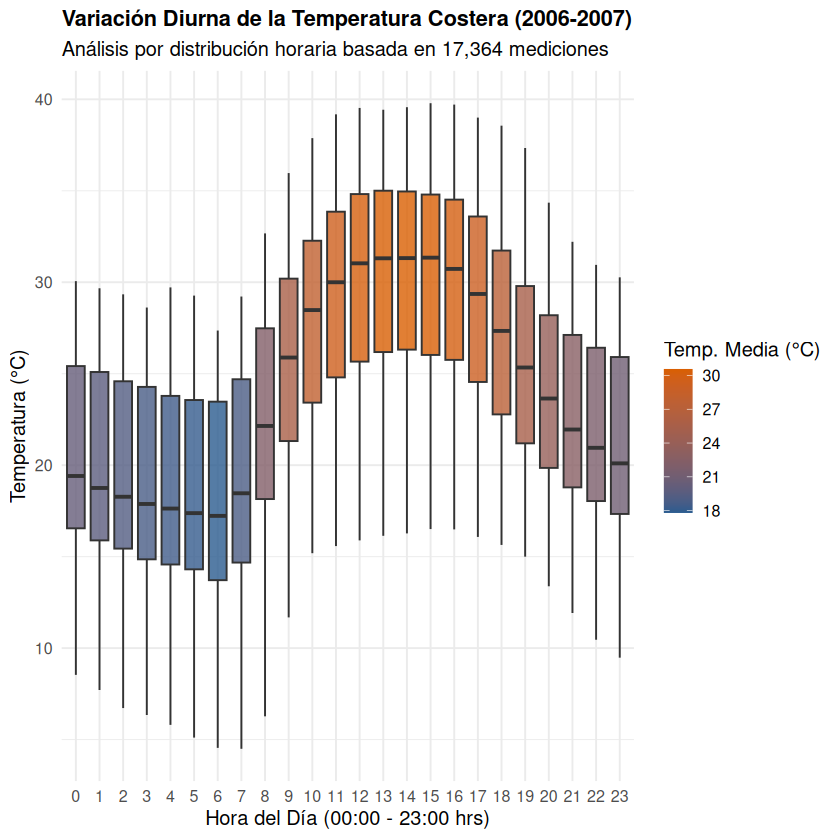

In [19]:
# Renderizar y Guardar Figura 1 en figuras
print(figura1)
ggsave("figuras/figura1_temperatura_diurna.png", plot = figura1, width = 8, height = 5, dpi = 300)

In [20]:
## Generación de la Figura 2. Regresión Lineal humedad relativa respecto a la temperatura
figura2 <- ggplot(datos_meteo, aes(x = rel_hum, y = temperature)) +
  geom_point(alpha = 0.15, color = "#2c7fb8", size = 1) +
  geom_smooth(method = "lm", color = "#e31a1c", linewidth = 1.2, se = TRUE) +
  theme_minimal(base_size = 12) +
  labs(title = "Relación Inversa entre Humedad Relativa y Temperatura",
    subtitle = "Ajuste lineal de covariación microclimática costera",
    x = "Humedad Relativa (%)",
    y = "Temperatura (°C)") +
  theme(plot.title = element_text(face = "bold", size = 13))

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


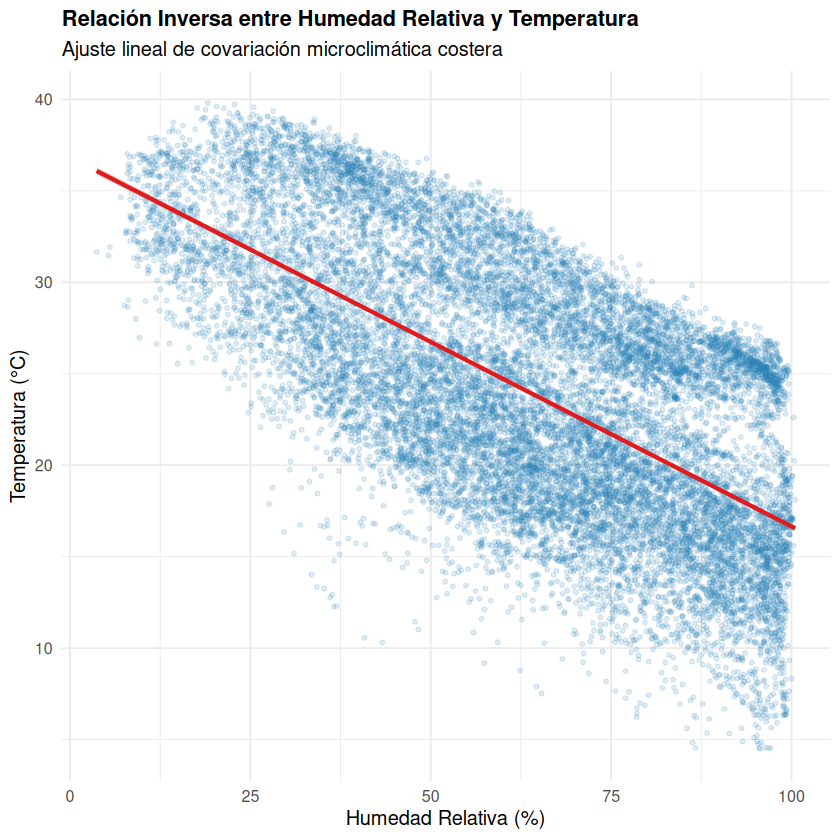

In [21]:
# Renderizar y Guardar Figura 2 en figuras/
print(figura2)
ggsave("figuras/figura2_humedad_temperatura.png", plot = figura2, width = 8, height = 5, dpi = 300)

In [22]:
### Generación de la Figura 3. Dinámica de velocidad del viento en comparación con la temperatura
figura3 <- ggplot(datos_meteo, aes(x = wind_spd, y = temperature)) +
  geom_point(alpha = 0.15, color = "#41b6c4", size = 1) +
  geom_smooth(method = "gam", color = "#253494", linewidth = 1.2, se = TRUE) +
  theme_minimal(base_size = 12) +
  labs(title = "Relación entre la Velocidad del Viento y la Temperatura",
    subtitle = "Ajuste no lineal mediante Modelos Aditivos Generalizados (GAM)",
    x = "Velocidad del Viento (m/s)",
    y = "Temperatura (°C)") +
  theme(plot.title = element_text(face = "bold", size = 13))

`geom_smooth()` using formula = 'y ~ s(x, bs = "cs")'
`geom_smooth()` using formula = 'y ~ s(x, bs = "cs")'



 Todas las figuras gráficas han sido guardadas con éxito en la carpeta figuras/


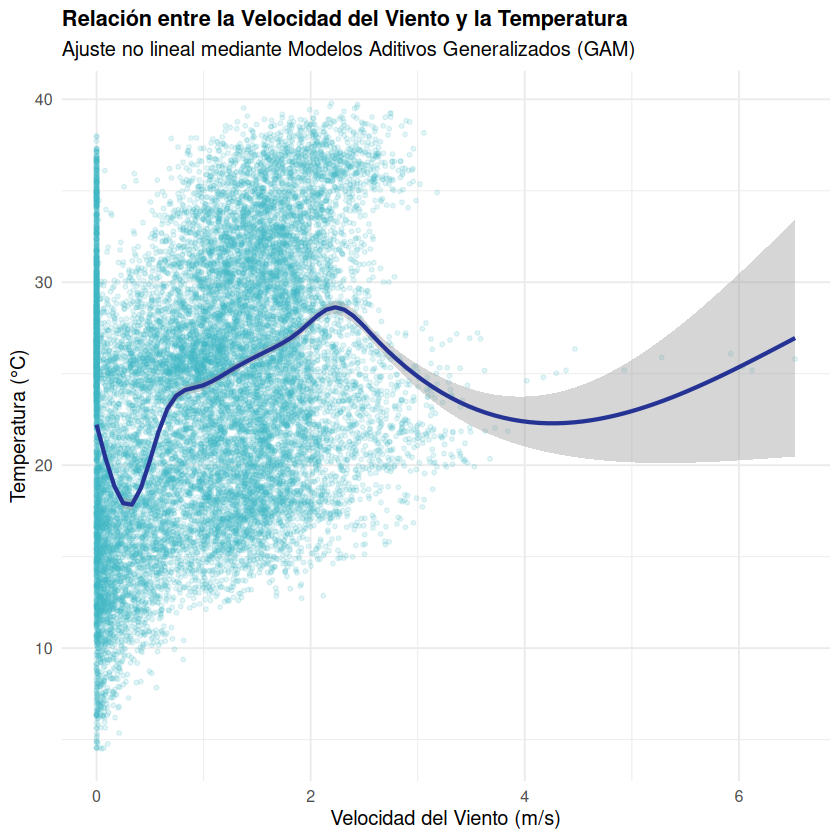

In [24]:
# Renderizar y Guardar Figura 3 en figuras/
print(figura3)
ggsave("figuras/figura3_viento_temperatura.png", plot = figura3, width = 8, height = 5, dpi = 300)

cat("\n Todas las figuras gráficas han sido guardadas con éxito en la carpeta figuras/\n")

In [25]:
# CONCLUSIONES GENERALES DEL PROYECTO 

# Los datos obtenidos indican la serie meteorológica registra una clara oscilación diurna con valores mínimos al amanecer (05:00-06:00 hrs, ~17.8 °C) 
# y picos térmicos en las horas de máxima insolación (13:00-15:00 hrs, ~30.5 °C). Así como un acoplamiento termohigrométrico inverso, ya que existe una
# sólida relación inversa entre la humedad relativa y la temperatura, donde los incrementos térmicos reducen la humedad relativa debido a la capacidad de
# saturación de la masa de aire costera. Por último, los valores del regimén de los vientos y la vetilación sugieren que las mayores velocidades del viento ocuerren en las horas más cálidas del día, favoreciendo el 
# mezclado vertical en la interfaz mar-aire.#